# Task 4.1


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
FAST = True


In [2]:
def leg(x, q):
    x = np.asarray(x, dtype=float)
    z = np.zeros(x.shape + (q + 1,))
    z[..., 0] = 1
    if q > 0:
        z[..., 1] = x
    for k in range(2, q + 1):
        z[..., k] = ((2*k - 1)*x*z[..., k-1] - (k-1)*z[..., k-2]) / k
    return z


def gen(n, q, v, r, rng):
    a = rng.normal(size=(r, q + 1))
    s = np.sqrt(np.sum(a**2 / (2*np.arange(q + 1) + 1), axis=1))
    a = a / s[:, None]
    x = rng.uniform(-1, 1, size=(r, n))
    y = np.sum(leg(x, q) * a[:, None, :], axis=2)
    y = y + np.sqrt(v) * rng.normal(size=(r, n))
    return x, y, a


def eout(a, w, v=0):
    p = max(a.shape[-1], w.shape[-1])
    aa = np.zeros(a.shape[:-1] + (p,))
    ww = np.zeros(w.shape[:-1] + (p,))
    aa[..., :a.shape[-1]] = a
    ww[..., :w.shape[-1]] = w
    return v + np.sum((ww - aa)**2 / (2*np.arange(p) + 1), axis=-1)


def stat(x, axis=0):
    x = np.asarray(x)
    return x.mean(axis=axis), x.std(axis=axis, ddof=1) / np.sqrt(x.shape[axis])


In [3]:
rng0 = np.random.default_rng(408)
x0 = np.linspace(-1, 1, 31)
z0 = leg(x0, 50)
for q in range(51):
    a0 = np.zeros(q + 1)
    a0[-1] = 1
    assert np.allclose(z0[:, q], np.polynomial.legendre.legval(x0, a0))
x0, y0, a0 = gen(30, 20, 0.1, 5, rng0)
assert np.allclose(np.sum(a0**2 / (2*np.arange(21) + 1), axis=1), 1)
x0, s0 = np.polynomial.legendre.leggauss(80)
w0 = rng0.normal(size=(5, 11))
d0 = a0 @ leg(x0, 20).T - w0 @ leg(x0, 10).T
assert np.allclose(eout(a0, w0, 0.1), d0**2 @ s0 / 2 + 0.1, atol=1e-10)


In [4]:
def delta(n, q, v, r, rng):
    x, y, a = gen(n, q, v, r, rng)
    z = leg(x, 10)

    w2 = (np.linalg.pinv(z[:, :, :3]) @ y[:, :, None])[:, :, 0]
    w10 = (np.linalg.pinv(z) @ y[:, :, None])[:, :, 0]
    return eout(a, w10, v) - eout(a, w2, v)

R = 500 if FAST else 1000
ns = np.arange(20, 131, 5)
vs = np.arange(21) / 10
qs = np.arange(1, 51)
rng = np.random.default_rng(407)
rnd = np.zeros((len(vs), len(ns), 2))
det = np.zeros((len(qs), len(ns), 2))


In [5]:
for i, v in enumerate(vs):
    for j, n in enumerate(ns):
        d = delta(n, 20, v, R, rng)
        rnd[i, j] = stat(d)
    if i % 5 == 0:
        print(f"Random noise: completed variance {v:.1f}", flush=True)

for i, q in enumerate(qs):
    for j, n in enumerate(ns):
        d = delta(n, q, 0.1, R, rng)
        det[i, j] = stat(d)
    if q % 10 == 0:
        print(f"Target complexity: completed degree {q}", flush=True)

assert np.isfinite(rnd).all() and np.isfinite(det).all()


Random noise: completed variance 0.0
Random noise: completed variance 0.5
Random noise: completed variance 1.0
Random noise: completed variance 1.5
Random noise: completed variance 2.0
Target complexity: completed degree 10
Target complexity: completed degree 20
Target complexity: completed degree 30
Target complexity: completed degree 40
Target complexity: completed degree 50


A: N=20, variance=0.0: 1.8729e+06 +/- 1.66e+06 SE
A: N=130, variance=0.0: -0.22427 +/- 0.0165 SE
A: N=20, variance=2.0: 3.772e+07 +/- 3.32e+07 SE
A: N=130, variance=2.0: -0.091046 +/- 0.0197 SE
B: N=130, Qf=1: 0.0090812 +/- 0.000715 SE
B: N=130, Qf=10: -0.38705 +/- 0.0113 SE
B: N=20, Qf=50: 4.8765e+05 +/- 2.57e+05 SE
B: N=130, Qf=50: -0.12204 +/- 0.0286 SE


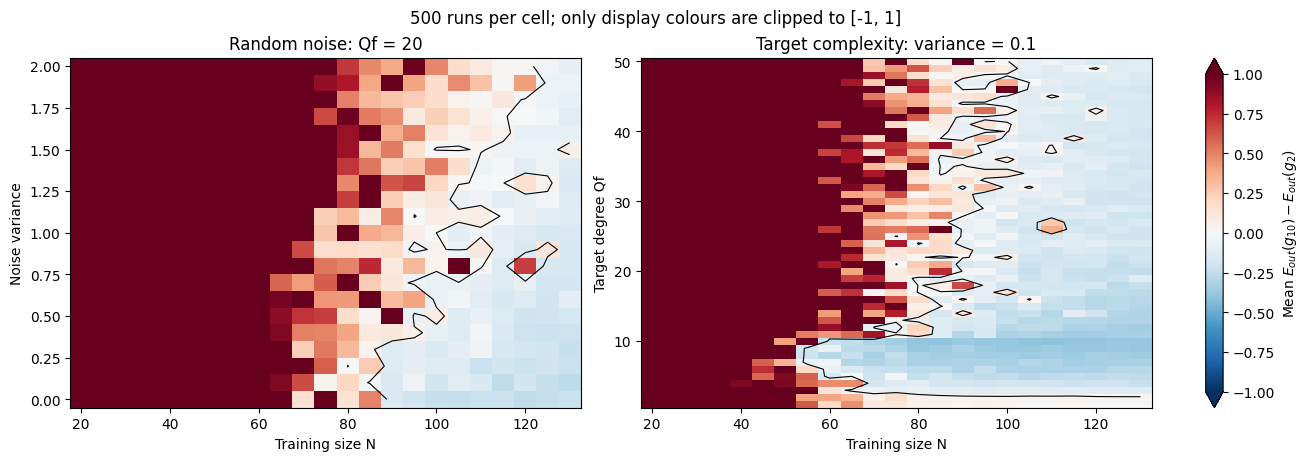

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
plots = [(vs, rnd, "Random noise: Qf = 20", "Noise variance"),
          (qs, det, "Target complexity: variance = 0.1", "Target degree Qf")]
for ax, (ys, res, ttl, ylab) in zip(axs, plots):
    m = res[:, :, 0]
    im = ax.pcolormesh(ns, ys, m, shading="nearest",
                         cmap="RdBu_r", vmin=-1, vmax=1)
    if m.min() < 0 < m.max():
        ax.contour(ns, ys, m, levels=[0], colors="black", linewidths=0.8)
    ax.set(xlabel="Training size N", ylabel=ylab, title=ttl)
fig.colorbar(im, ax=axs, extend="both", label=r"Mean $E_{out}(g_{10})-E_{out}(g_2)$")
fig.suptitle(f"{R} runs per cell; only display colours are clipped to [-1, 1]")
plt.show()

for i, j in [(0, 0), (0, -1), (-1, 0), (-1, -1)]:
    m, se = rnd[i, j]
    print(f"A: N={ns[j]}, variance={vs[i]}: {m:.5g} +/- {se:.3g} SE")
for i, j in [(0, -1), (9, -1), (-1, 0), (-1, -1)]:
    m, se = det[i, j]
    print(f"B: N={ns[j]}, Qf={qs[i]}: {m:.5g} +/- {se:.3g} SE")
